# CXC102

In [1]:
import os 
import sys
from dotenv import load_dotenv
from tensorflow.keras import layers, models
import tensorflow as tf 
print(tf.__version__)
print(tf.config.list_physical_devices("GPU"))
 
module_path = os.path.abspath(os.path.join('../../'))
if module_path not in sys.path:
    # adds the 'src' directory to the python path
    sys.path.append(module_path)
# from src.utils.ds_helper import get_dataset_distribution


2.16.1
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### Load dataset 

In [2]:
load_dotenv()
dataset_path = os.getenv("DATASET_DIR")
model_path = os.getenv("MODEL_DIR")

MODEL_NAME = "CXC102.keras"
model = os.path.join(model_path, MODEL_NAME)

train_data_dir = os.path.join(dataset_path, "data03", "train")
test_data_dir = os.path.join(dataset_path, "data03", "test")
val_data_dir = os.path.join(dataset_path, "data03", "val")


# Set parameters
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

print(train_data_dir)
print(test_data_dir)
print(val_data_dir)



/Users/joshan/Documents/final-year-project/dataset/data03/train
/Users/joshan/Documents/final-year-project/dataset/data03/test
/Users/joshan/Documents/final-year-project/dataset/data03/val


In [3]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_data_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical' # Important for 3-class classification
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_data_dir,
    image_size=(224, 224),
    batch_size=32,
    label_mode='categorical'
)

val_ds = tf.keras.utils.image_dataset_from_directory(
   val_data_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

Found 13028 files belonging to 4 classes.
Found 1527 files belonging to 4 classes.


2026-04-04 13:15:58.991383: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M3
2026-04-04 13:15:58.991410: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-04-04 13:15:58.991413: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
2026-04-04 13:15:58.992032: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-04-04 13:15:58.992051: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Found 761 files belonging to 4 classes.


### CNN model Architecture

In [4]:
model = models.Sequential([
    # Preprocessing: Rescale inputs to [0, 1]
    layers.Rescaling(1./255, input_shape=(224, 224, 3)),
    
    # First convolutional Block
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Second convolutional Block
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Third convolutional Block
    layers.Conv2D(192, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Flatten and Classify
    layers.Flatten(),
    layers.Dense(128, activation='relu'),  
    layers.Dropout(0.4), # Helps prevent overfitting by dropping out 0.5 acc 
    layers.Dense(4, activation='softmax') # Softmax for multi-class probability
])

/Users/joshan/Documents/final-year-project/backend/.venv/lib/python3.11/site-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [5]:
import keras


# Define the early stopping monitor
# This stops training if 'val_loss' doesn't improve for 3 epochs
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', 
    patience=3, 
    restore_best_weights=True
)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    train_ds,
    validation_data=val_ds, # evaluating against val dataset
    epochs=10
)

Epoch 1/10


2026-04-04 13:15:59.870996: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


408/408 ━━━━━━━━━━━━━━━━━━━━ 76s 180ms/step - accuracy: 0.7196 - loss: 0.7384 - val_accuracy: 0.8870 - val_loss: 0.3266
Epoch 2/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 57s 139ms/step - accuracy: 0.8234 - loss: 0.6165 - val_accuracy: 0.9080 - val_loss: 0.4035
Epoch 3/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 55s 135ms/step - accuracy: 0.8369 - loss: 0.7815 - val_accuracy: 0.9106 - val_loss: 0.5183
Epoch 4/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 55s 135ms/step - accuracy: 0.8496 - loss: 0.8982 - val_accuracy: 0.9014 - val_loss: 0.6325
Epoch 5/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 55s 134ms/step - accuracy: 0.8518 - loss: 1.3296 - val_accuracy: 0.9067 - val_loss: 0.9870
Epoch 6/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 55s 134ms/step - accuracy: 0.8512 - loss: 2.1058 - val_accuracy: 0.8962 - val_loss: 1.6871
Epoch 7/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 55s 133ms/step - accuracy: 0.8468 - loss: 3.0836 - val_accuracy: 0.8660 - val_loss: 2.6331
Epoch 8/10
408/408 ━━━━━━━━━━━━━━━━━━━━ 56s 136ms/step - accuracy: 0.8541 - loss: 4.0267 - val

In [6]:
# Save the model
model.save('CXC102.keras')
print("Model saved successfully!")

Model saved successfully!


In [7]:
# model_path = os.getenv("MODEL_DIR")
model = os.path.join("CXC102.keras")
print(model)
model = tf.keras.models.load_model(model)


CXC102.keras


In [8]:
# Evaludate against test data
results = model.evaluate(test_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - accuracy: 0.9234 - loss: 2.5557
Test Loss: 2.555711030960083
Test Accuracy: 92.34%


In [9]:
# evaluated against validation dataset
results = model.evaluate(val_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - accuracy: 0.9198 - loss: 3.9177
Test Loss: 3.917724609375
Test Accuracy: 91.98%


2026-04-04 19:13:26.800086: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


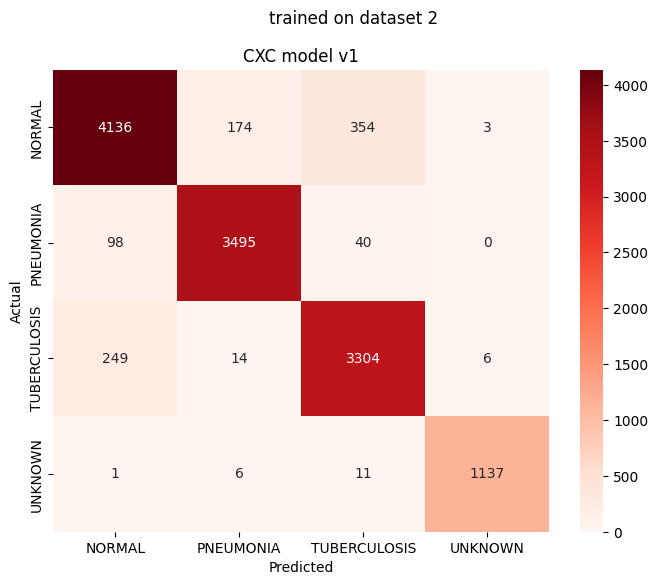

              precision    recall  f1-score   support

      NORMAL       0.92      0.89      0.90      4667
   PNEUMONIA       0.95      0.96      0.95      3633
TUBERCULOSIS       0.89      0.92      0.91      3573
     UNKNOWN       0.99      0.98      0.99      1155

    accuracy                           0.93     13028
   macro avg       0.94      0.94      0.94     13028
weighted avg       0.93      0.93      0.93     13028



In [11]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Get all predictions and true labels
y_pred = []
y_true = []

for images, labels in train_ds:
    preds = model.predict(images, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(np.argmax(labels, axis=1))

# Generate the Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
class_names = test_ds.class_names

# Plot them in heat map
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', 
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('CXC102 model')
plt.suptitle("trained on dataset 2")
plt.show()

# Print Precision, Recall, and F1-Score
print(classification_report(y_true, y_pred, target_names=class_names))